In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import scanpy as sc
import scFates as scf
import matplotlib.pyplot as plt

In [2]:
geo = 'GSE159478'
pth = os.path.join('..', '..', '..')
pth_in = os.path.join(pth, 'data', 'cancer', 'vertebrate', geo)
pth_out = os.path.join(pth, 'figures', 'cancer', 'vertebrate', geo)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'MMTV-PyMT.h5ad'))
adata

AnnData object with n_obs × n_vars = 1242 × 26602
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'celltype_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

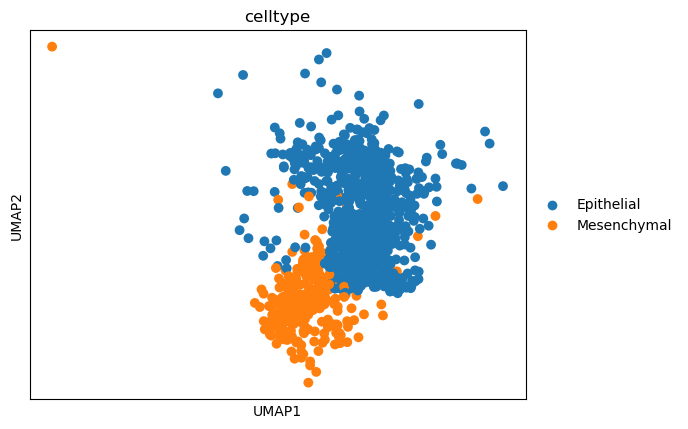

In [4]:
sc.pl.umap(adata, color = 'celltype', size = 200)

inferring a principal curve --> parameters used 
    30 principal points, mu = 350, lambda = 0.01
    finished (0:00:02) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.


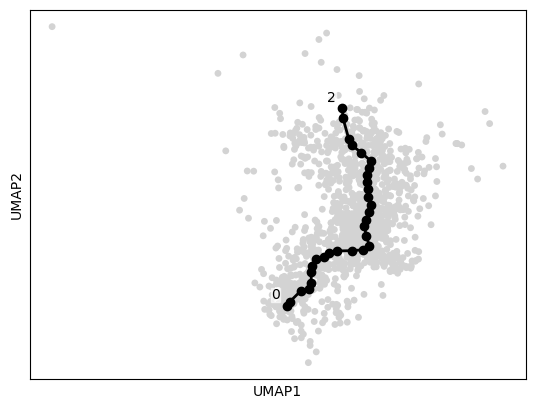

In [5]:
scf.tl.curve(adata, Nodes = 30, epg_lambda = 1e-2, epg_mu = 350, use_rep = 'umap', plot = True, basis = 'umap')

In [6]:
scf.tl.root(adata, 2)

node 2 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.


In [7]:
scf.tl.pseudotime(adata)

projecting cells onto the principal graph
    finished (0:00:00) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.


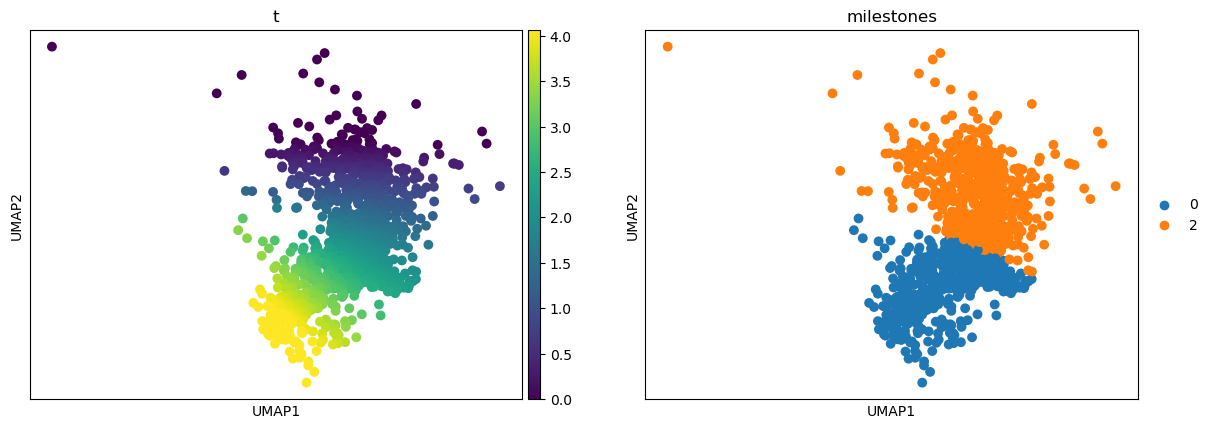

In [8]:
sc.pl.umap(adata, color = ['t', 'milestones'], size = 200)

/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


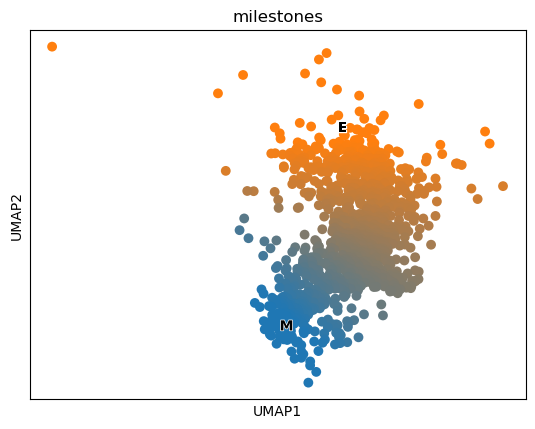

In [9]:
scf.tl.rename_milestones(adata, new = {'0' : 'M', '2' : 'E'})
scf.pl.milestones(adata, basis = 'umap', annotate = True, s = 200)

In [10]:
del adata.uns['epg']
adata.write(os.path.join(pth_in, 'trajectory.h5ad'))

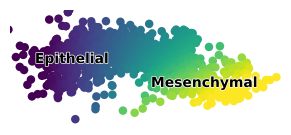

In [11]:
s = 150
fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.umap(adata, dimensions = [1, 0], color = 't', size = s,
           colorbar_loc = None, frameon = False, show = False,
           ax = ax)
sc.pl.umap(adata, dimensions = [1, 0], color = 'celltype', alpha = 0,
           legend_loc = 'on data', legend_fontoutline = 1, frameon = False,
           show = False, ax = ax)
ax.invert_xaxis(); ax.set_title('')
xlim = ax.get_xlim(); ylim = ax.get_ylim()
ax.set_xlim((xlim[0] - 1.5, xlim[1] + .45))
ax.set_ylim((ylim[0] + 3.9, ylim[1] - 1.35))

pos_dict = {
    'Epithelial'  : (1.2, -.15),
    'Mesenchymal' : (.1, 0)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_out, 'trajectory.pdf')
plt.savefig(fn, bbox_inches = 'tight')